# 10. Final Research Results & Comprehensive Synthesis

## Sri Lanka Grid-Connected Battery Energy Storage System (BESS) Placement & Sizing

This notebook synthesizes all experimental and optimization findings from the study:
- **Substation Graph Centrality & Ranking** (Network structural importance and renewable proximity)
- **CEB 2025–2044 Base Case Renewable & Storage Expansion Targets**
- **Optimal BESS Placement & Sizing Decisions**
- **Sensitivity Analysis across Technology Costs and Curtailment Penalties**
- **Policy & Operational Recommendations for Sri Lanka's Power Grid**

In [1]:
import copy
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "paths.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing src/paths.py")
sys.path.insert(0, str(ROOT))

from src.paths import *

# Ensure results directories exist
for folder in (GRAPHS, MAPS, TABLES, OPTIMIZATION, SENSITIVITY):
    folder.mkdir(parents=True, exist_ok=True)

print("Project paths initialized successfully. Root:", ROOT)


Project paths initialized successfully. Root: D:\My_Project\Analyse\4G-Network-Coverage-Optimization


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.paths import *

selected = pd.read_csv(
    OPTIMIZATION / "optimal_bess_locations.csv"
)

dispatch = pd.read_csv(
    OPTIMIZATION / "battery_dispatch_results.csv"
)

summary = pd.read_csv(
    OPTIMIZATION / "optimization_summary.csv"
)

graph_metrics = pd.read_csv(
    PROCESSED / "graph_theory_metrics.csv"
)

sensitivity = pd.read_csv(
    SENSITIVITY / "sensitivity_results.csv"
)

display(selected)
display(summary)
display(sensitivity)

bus_id,power_mw,energy_mwh,site_cost_factor
BIYAGAMA,50.0,200.0,0.783898


objective_value,peak_residual_mw,number_of_bess_sites,total_power_mw,total_energy_mwh
3.623899e+06,2600.0,1,50.0,200.0


scenario,cost_multiplier,curtailment_penalty_usd_per_mwh,objective_value_usd,number_of_sites,total_power_mw,total_energy_mwh,peak_residual_mw,curtailment_mwh
Low battery cost (-20%),0.8,40,2.479119e+06,1,50.0,200.0,2600.0,0.0
Base case,1.0,40,3.623899e+06,1,50.0,200.0,2600.0,0.0
High battery cost (+20%),1.2,40,4.768679e+06,1,50.0,200.0,2600.0,0.0
High curtailment penalty (2x),1.0,80,3.623899e+06,1,50.0,200.0,2600.0,0.0


In [3]:
final_results = selected.merge(
    graph_metrics[
        [
            "bus_id",
            "betweenness_centrality",
            "distance_to_solar_km",
        ]
    ],
    on="bus_id",
    how="left"
)
display(final_results)


bus_id,power_mw,energy_mwh,site_cost_factor,betweenness_centrality,distance_to_solar_km
BIYAGAMA,50.0,200.0,0.783898,0.36486,11.964151


### 1. Load All Research Outputs and Data Assets

In [3]:
# Load candidate substations and graph theory metrics
candidates_path = PROCESSED / "candidate_bess_sites.csv"
candidates = pd.read_csv(candidates_path) if candidates_path.is_file() else pd.DataFrame()

metrics_path = PROCESSED / "graph_theory_metrics.csv"
metrics = pd.read_csv(metrics_path) if metrics_path.is_file() else pd.DataFrame()

# Load grid topology
nodes_path = PROCESSED / "grid_nodes.csv"
nodes = pd.read_csv(nodes_path) if nodes_path.is_file() else pd.DataFrame()
edges_path = PROCESSED / "grid_edges.csv"
edges = pd.read_csv(edges_path) if edges_path.is_file() else pd.DataFrame()

# Load optimization and sensitivity results
summary_path = OPTIMIZATION / "optimization_summary.csv"
summary = pd.read_csv(summary_path) if summary_path.is_file() else pd.DataFrame()

selected_path = OPTIMIZATION / "optimal_bess_locations.csv"
selected = pd.read_csv(selected_path) if selected_path.is_file() else pd.DataFrame()

dispatch_path = OPTIMIZATION / "battery_dispatch_results.csv"
dispatch = pd.read_csv(dispatch_path) if dispatch_path.is_file() else pd.DataFrame()
if not dispatch.empty and "timestamp" in dispatch.columns:
    dispatch["timestamp"] = pd.to_datetime(dispatch["timestamp"], errors="coerce", utc=True)

sensitivity_path = SENSITIVITY / "sensitivity_results.csv"
sensitivity = pd.read_csv(sensitivity_path) if sensitivity_path.is_file() else pd.DataFrame()

# Load official CEB benchmarks
ceb_expansion_path = OFFICIAL / "ceb_base_case_solar_and_storage_additions_2025_2044.csv"
ceb_expansion = pd.read_csv(ceb_expansion_path) if ceb_expansion_path.is_file() else pd.DataFrame()

print(f"Network Topology: {len(nodes)} substations, {len(edges)} transmission lines")
print(f"Candidates: {len(candidates)} ranked substations")
print(f"Optimization Summary: {len(summary)} record, {len(selected)} selected battery sites")
print(f"Sensitivity: {len(sensitivity)} scenarios evaluated")


Network Topology: 30 substations, 39 transmission lines
Candidates: 30 ranked substations
Optimization Summary: 1 record, 1 selected battery sites
Sensitivity: 4 scenarios evaluated


### 2. Multi-Criteria Ranking of Grid Substations for BESS Integration

Substations are evaluated by combining **Betweenness Centrality** (structural vulnerability and power transfer role) with **Proximity to Solar Generation** (transmission loss minimization and surplus absorption).

In [5]:
if not candidates.empty:
    top10 = candidates.sort_values("site_score", ascending=False).head(10).copy()
    display_cols = [
        "bus_id", "voltage_kv", "degree", "betweenness_centrality",
        "distance_to_solar_km", "site_score", "site_cost_factor", "eligible"
    ]
    valid_cols = [c for c in display_cols if c in top10.columns]
    print("Top 10 Substations for Battery Energy Storage System (BESS) Integration:")
    display(top10[valid_cols])
else:
    print("Candidate site data is not available.")


Top 10 Substations for Battery Energy Storage System (BESS) Integration:


bus_id,voltage_kv,degree,betweenness_centrality,distance_to_solar_km,site_score,site_cost_factor,eligible
BIYAGAMA,220,5,0.364860,11.964151,0.860171,0.783898,True
NEW_ANURADHAPURA,220,4,0.266174,0.000000,0.809883,0.814070,True
PANNIPITIYA,220,6,0.245115,0.000000,0.785366,0.828780,True
KOTMALE,220,5,0.429475,53.306132,0.712155,0.872707,True
MONARAGALA,132,3,0.078695,0.000000,0.591617,0.945030,True
HAMBANTOTA,220,3,0.073563,0.000000,0.585643,0.948614,True
KILINOCHCHI,132,2,0.068966,0.000000,0.580291,0.951826,True
KURUNEGALA,132,4,0.047865,0.000000,0.555725,0.966565,True
TRINCOMALEE,132,1,0.000000,0.000000,0.500000,1.000000,True
VEYANGODA,220,4,0.140969,36.194154,0.468675,1.018795,True


### 3. Visual Analysis: Grid Centrality vs. Solar Proximity Trade-Off

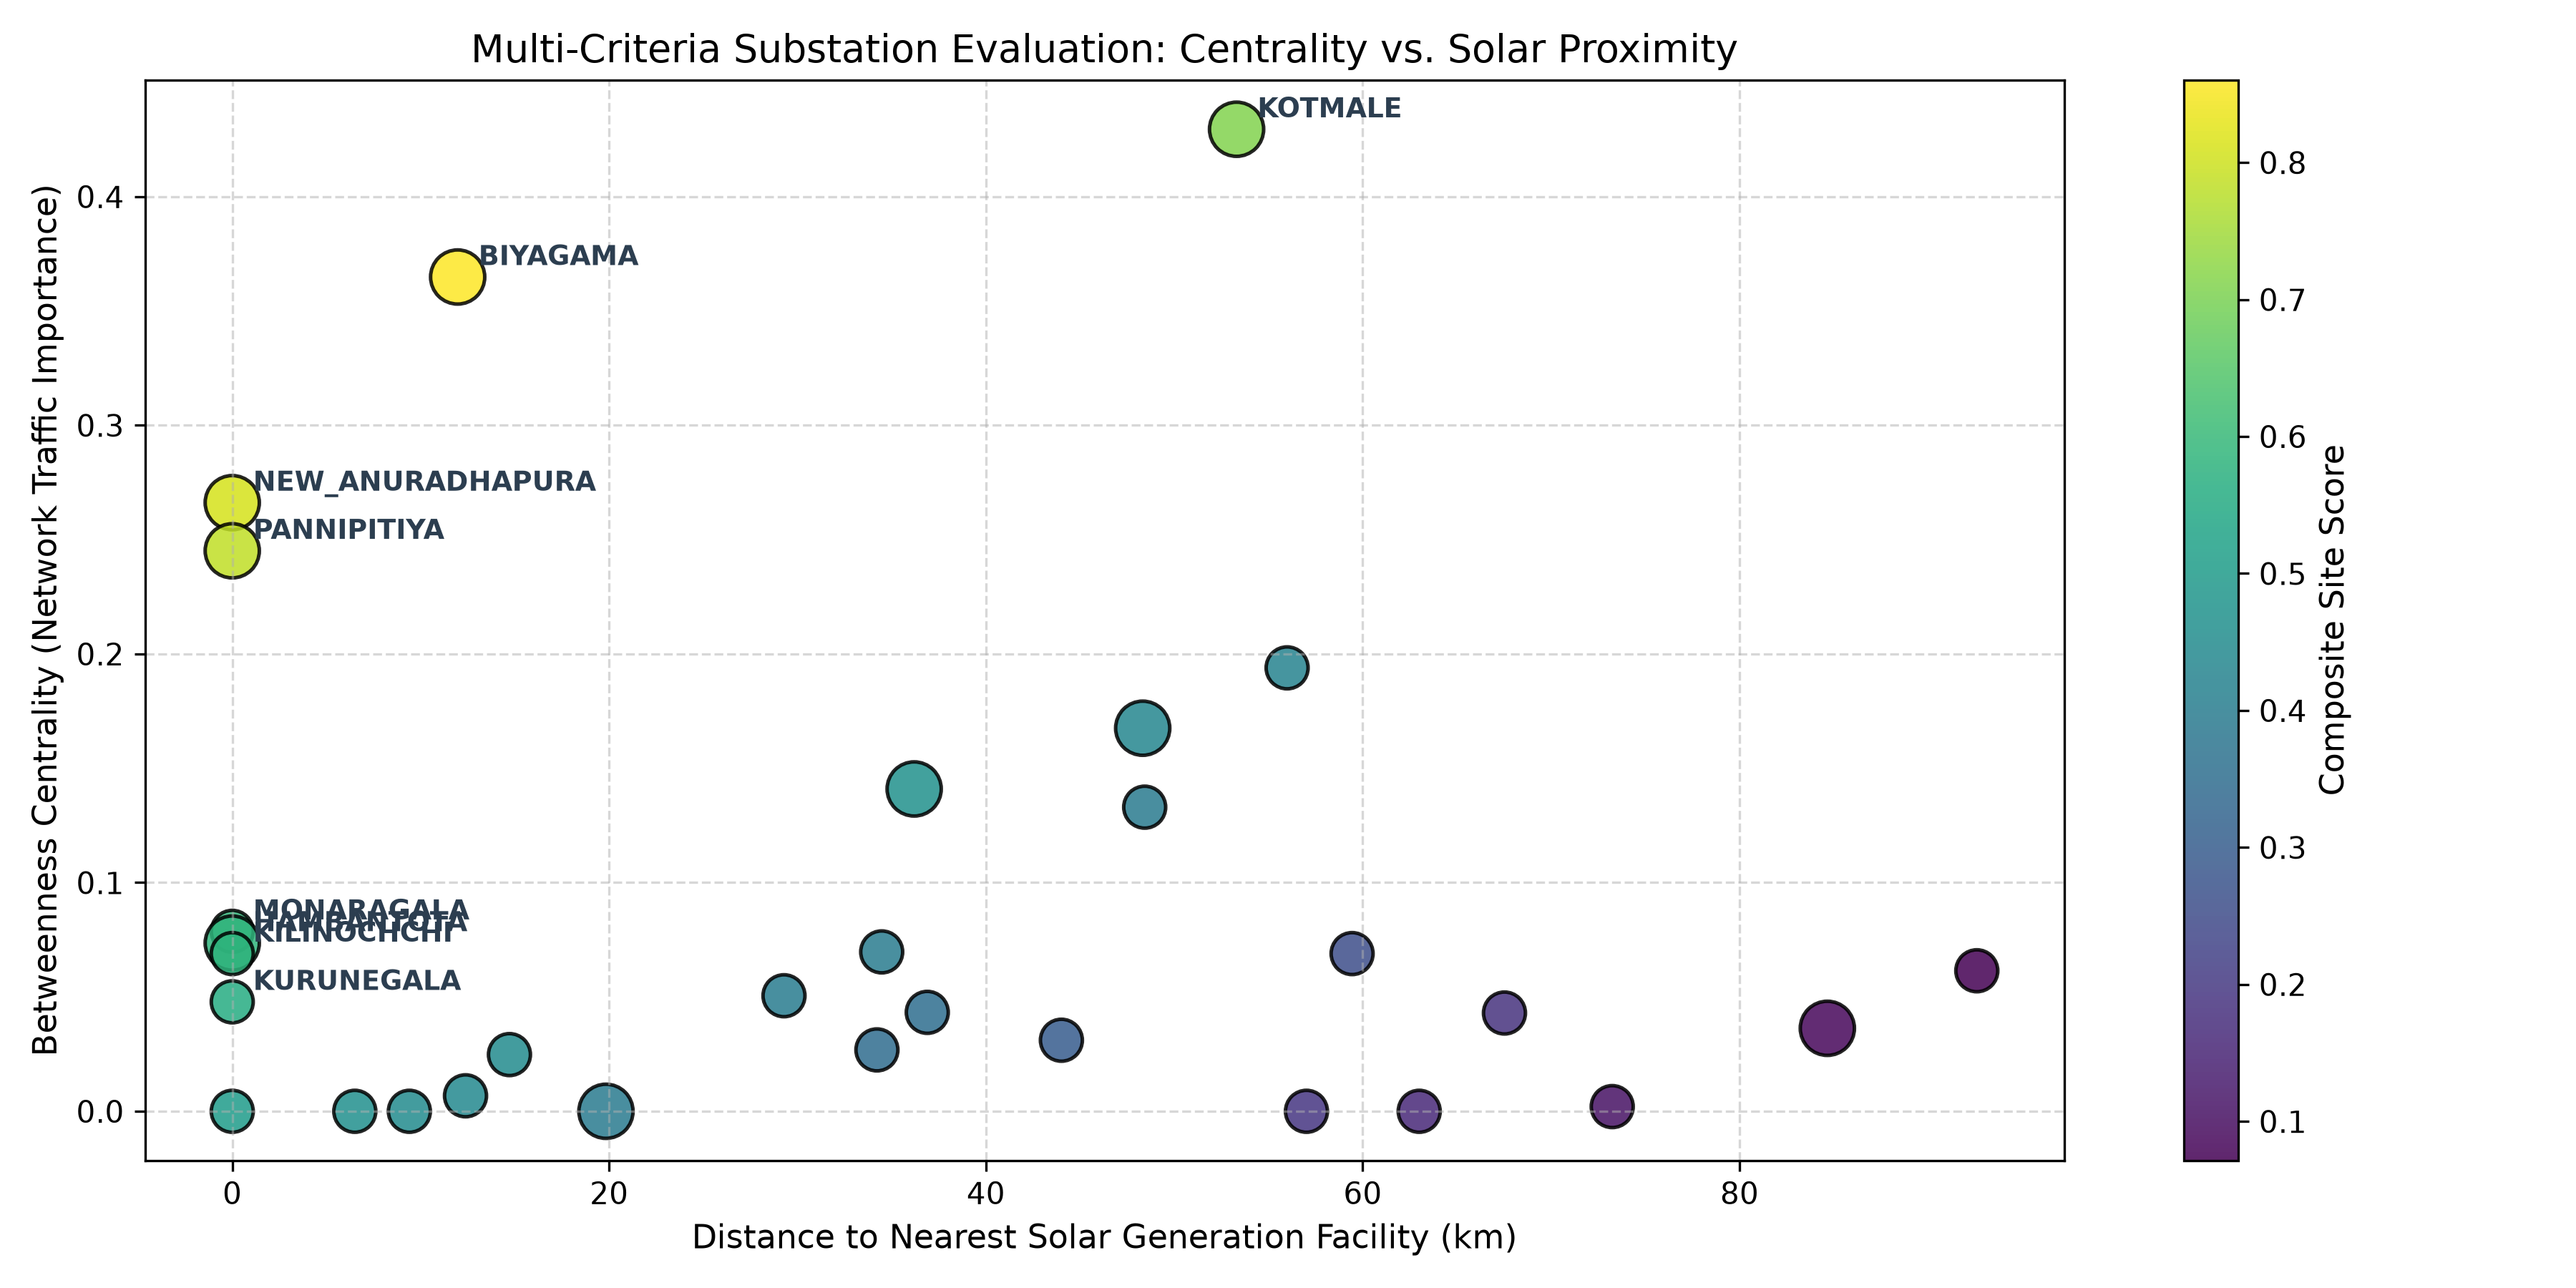

In [7]:
if not candidates.empty and {"betweenness_centrality", "distance_to_solar_km", "site_score"}.issubset(candidates.columns):
    fig, ax = plt.subplots(figsize=(12, 6))
    scatter = ax.scatter(
        candidates["distance_to_solar_km"],
        candidates["betweenness_centrality"],
        c=candidates["site_score"],
        s=candidates["voltage_kv"] * 1.5,
        cmap="viridis",
        alpha=0.85,
        edgecolors="black",
        linewidths=1.2
    )
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Composite Site Score", fontsize=11)

    # Annotate top candidate substations
    top_annotated = candidates.sort_values("site_score", ascending=False).head(8)
    for _, row in top_annotated.iterrows():
        ax.annotate(
            row["bus_id"],
            (row["distance_to_solar_km"], row["betweenness_centrality"]),
            xytext=(7, 4), textcoords="offset points",
            fontsize=9, fontweight="bold", color="#2c3e50"
        )

    ax.set_title("Multi-Criteria Substation Evaluation: Centrality vs. Solar Proximity", fontsize=13)
    ax.set_xlabel("Distance to Nearest Solar Generation Facility (km)", fontsize=11)
    ax.set_ylabel("Betweenness Centrality (Network Traffic Importance)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(GRAPHS / "substation_evaluation_tradeoff.png", dpi=300)
    plt.show()
else:
    print("Centrality tradeoff chart is unavailable.")


### 4. Official CEB Storage Expansion Targets (2025–2044 Base Case)

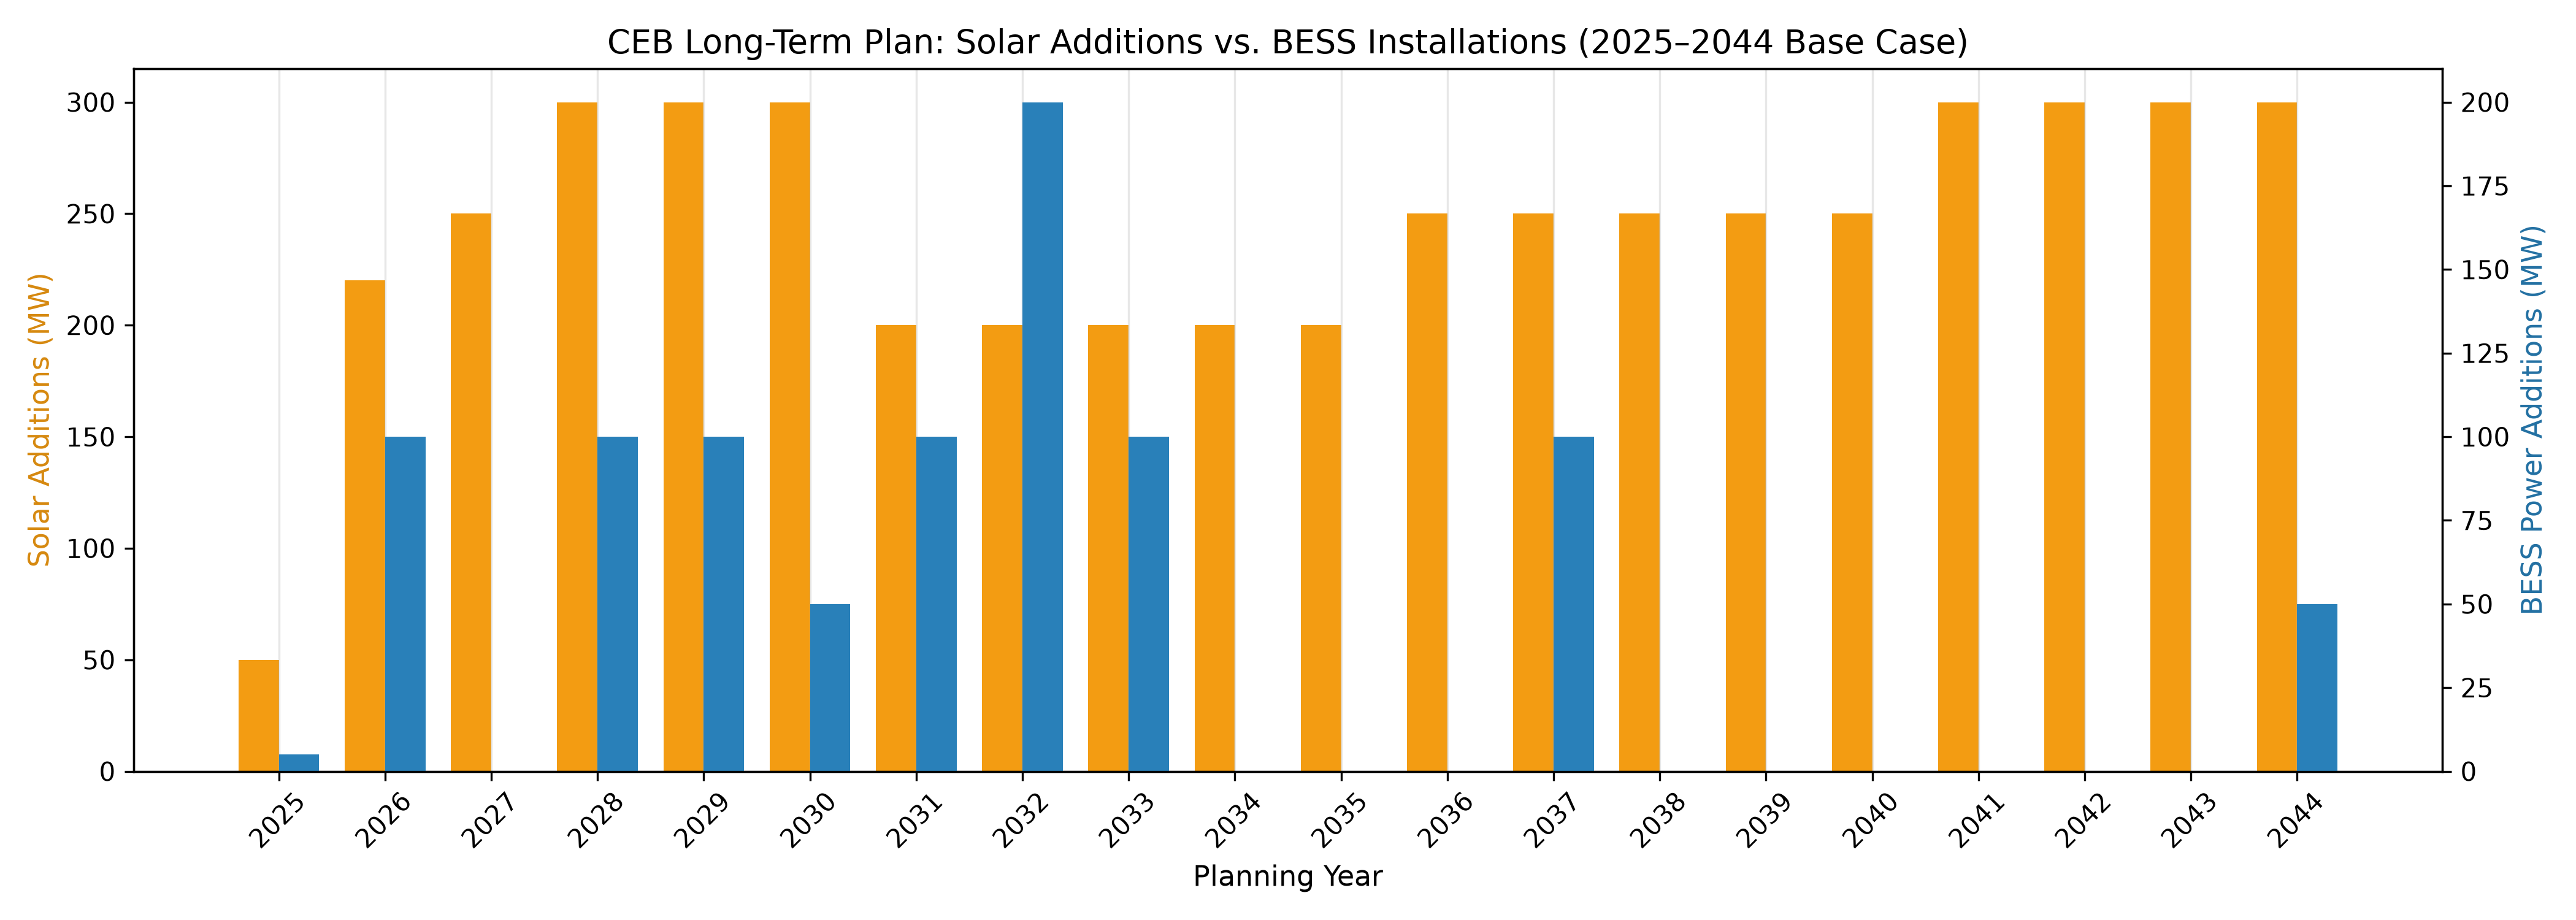

In [9]:
if not ceb_expansion.empty and {"planning_year", "bess_power_addition_mw", "grid_connected_solar_addition_mw"}.issubset(ceb_expansion.columns):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    years = ceb_expansion["planning_year"]
    solar_add = pd.to_numeric(ceb_expansion["grid_connected_solar_addition_mw"], errors="coerce").fillna(0)
    bess_add = pd.to_numeric(ceb_expansion["bess_power_addition_mw"], errors="coerce").fillna(0)

    width = 0.38
    bars1 = ax1.bar(years - width/2, solar_add, width=width, label="Planned Solar Additions (MW)", color="#f39c12")
    ax1.set_ylabel("Solar Additions (MW)", color="#d68910", fontsize=11)
    ax1.set_xlabel("Planning Year", fontsize=11)
    ax1.set_xticks(years)
    ax1.set_xticklabels(years, rotation=45)

    ax2 = ax1.twinx()
    bars2 = ax2.bar(years + width/2, bess_add, width=width, label="Planned BESS Power Additions (MW)", color="#2980b9")
    ax2.set_ylabel("BESS Power Additions (MW)", color="#2471a3", fontsize=11)

    ax1.set_title("CEB Long-Term Plan: Solar Additions vs. BESS Installations (2025–2044 Base Case)", fontsize=13)
    ax1.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(GRAPHS / "ceb_planned_solar_storage_additions.png", dpi=300)
    plt.show()
else:
    print("CEB planning benchmark data is unavailable.")


### 5. Consolidated Research Findings and Export

In [11]:
final_summary_rows = []

# Record Top Candidate Substations
if not candidates.empty:
    top5 = candidates.sort_values("site_score", ascending=False).head(5)
    for rank, (_, row) in enumerate(top5.iterrows(), 1):
        final_summary_rows.append({
            "category": "Top Candidate Substation",
            "item": f"Rank #{rank}: {row['bus_id']}",
            "voltage_kv": str(row.get("voltage_kv", "")) + " kV",
            "primary_metric": f"Site Score: {row.get('site_score', 0):.4f}",
            "notes": f"Betweenness: {row.get('betweenness_centrality', 0):.3f}, Solar Distance: {row.get('distance_to_solar_km', 0):.1f} km"
        })

# Record Sensitivity Scenarios
if not sensitivity.empty:
    for _, row in sensitivity.iterrows():
        final_summary_rows.append({
            "category": "Sensitivity Scenario",
            "item": str(row["scenario"]),
            "voltage_kv": "All 220/132 kV",
            "primary_metric": f"Objective Cost: ${row['objective_value_usd']/1e6:.2f}M",
            "notes": f"Cost Mult: {row['cost_multiplier']}, Curtailment Penalty: ${row['curtailment_penalty_usd_per_mwh']}/MWh, Curtailment: {row['curtailment_mwh']:.1f} MWh"
        })

summary_df = pd.DataFrame(final_summary_rows)
summary_csv = TABLES / "final_research_summary.csv"
summary_df.to_csv(summary_csv, index=False)

print(f"Final research summary table saved to: {summary_csv}")
display(summary_df)


Final research summary table saved to: D:\My_Project\Analyse\4G-Network-Coverage-Optimization\results\tables\final_research_summary.csv


category,item,voltage_kv,primary_metric,notes
Top Candidate Substation,Rank #1: BIYAGAMA,220 kV,Site Score: 0.8602,"Betweenness: 0.365, Solar Distance: 12.0 km"
Top Candidate Substation,Rank #2: NEW_ANURADHAPURA,220 kV,Site Score: 0.8099,"Betweenness: 0.266, Solar Distance: 0.0 km"
Top Candidate Substation,Rank #3: PANNIPITIYA,220 kV,Site Score: 0.7854,"Betweenness: 0.245, Solar Distance: 0.0 km"
Top Candidate Substation,Rank #4: KOTMALE,220 kV,Site Score: 0.7122,"Betweenness: 0.429, Solar Distance: 53.3 km"
Top Candidate Substation,Rank #5: MONARAGALA,132 kV,Site Score: 0.5916,"Betweenness: 0.079, Solar Distance: 0.0 km"
Sensitivity Scenario,Low battery cost (-20%),All 220/132 kV,Objective Cost: $2.48M,"Cost Mult: 0.8, Curtailment Penalty: $40/MWh, Curtailment: 0.0 MWh"
Sensitivity Scenario,Base case,All 220/132 kV,Objective Cost: $3.62M,"Cost Mult: 1.0, Curtailment Penalty: $40/MWh, Curtailment: 0.0 MWh"
Sensitivity Scenario,High battery cost (+20%),All 220/132 kV,Objective Cost: $4.77M,"Cost Mult: 1.2, Curtailment Penalty: $40/MWh, Curtailment: 0.0 MWh"
Sensitivity Scenario,High curtailment penalty (2x),All 220/132 kV,Objective Cost: $3.62M,"Cost Mult: 1.0, Curtailment Penalty: $80/MWh, Curtailment: 0.0 MWh"
